# 2. Ridge regression

**Learning goals**: closed form, the shrinkage view through the SVD, effective degrees of freedom,
why you must standardise, and how ridge treats correlated predictors.

$$\hat\beta^{\text{ridge}} = \arg\min_\beta \; \lVert y - X\beta \rVert^2 + \lambda \lVert\beta\rVert_2^2
= (X^\top X + \lambda I)^{-1} X^\top y$$

Adding $\lambda I$ makes the matrix invertible for any $\lambda > 0$, even when $p > n$.
The intercept is not penalised: centre $y$ and the columns of $X$ first.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

## Ridge from scratch vs scikit-learn

In [2]:
from sklearn.linear_model import Ridge
n, p = 50, 8
X = rng.normal(size=(n, p)); beta = np.array([3, -2, 0, 0, 1.5, 0, 0, 0.5])
y = X @ beta + rng.normal(size=n)
Xc, yc = X - X.mean(0), y - y.mean()
lam = 10.0
b_scratch = np.linalg.solve(Xc.T @ Xc + lam * np.eye(p), Xc.T @ yc)
b_sklearn = Ridge(alpha=lam).fit(X, y).coef_
print(np.round(b_scratch, 4)); print(np.round(b_sklearn, 4))
print("max difference:", np.abs(b_scratch - b_sklearn).max())

[ 2.2556 -1.7424 -0.0297  0.1945  1.245  -0.1015  0.0991  0.5837]
[ 2.2556 -1.7424 -0.0297  0.1945  1.245  -0.1015  0.0991  0.5837]
max difference: 4.440892098500626e-16


## The SVD view: ridge shrinks along principal directions
Write $X = U D V^\top$ (singular values $d_j$). Then the fitted values are
$$X\hat\beta^{\text{ridge}} = \sum_j u_j \, \frac{d_j^2}{d_j^2 + \lambda} \, u_j^\top y .$$
Each principal direction is shrunk by $d_j^2/(d_j^2+\lambda)$: directions with little variance in
$X$ (small $d_j$, where OLS is noisiest) are shrunk most. The **effective degrees of freedom**
$\text{df}(\lambda) = \sum_j d_j^2/(d_j^2+\lambda)$ fall smoothly from $p$ to 0.

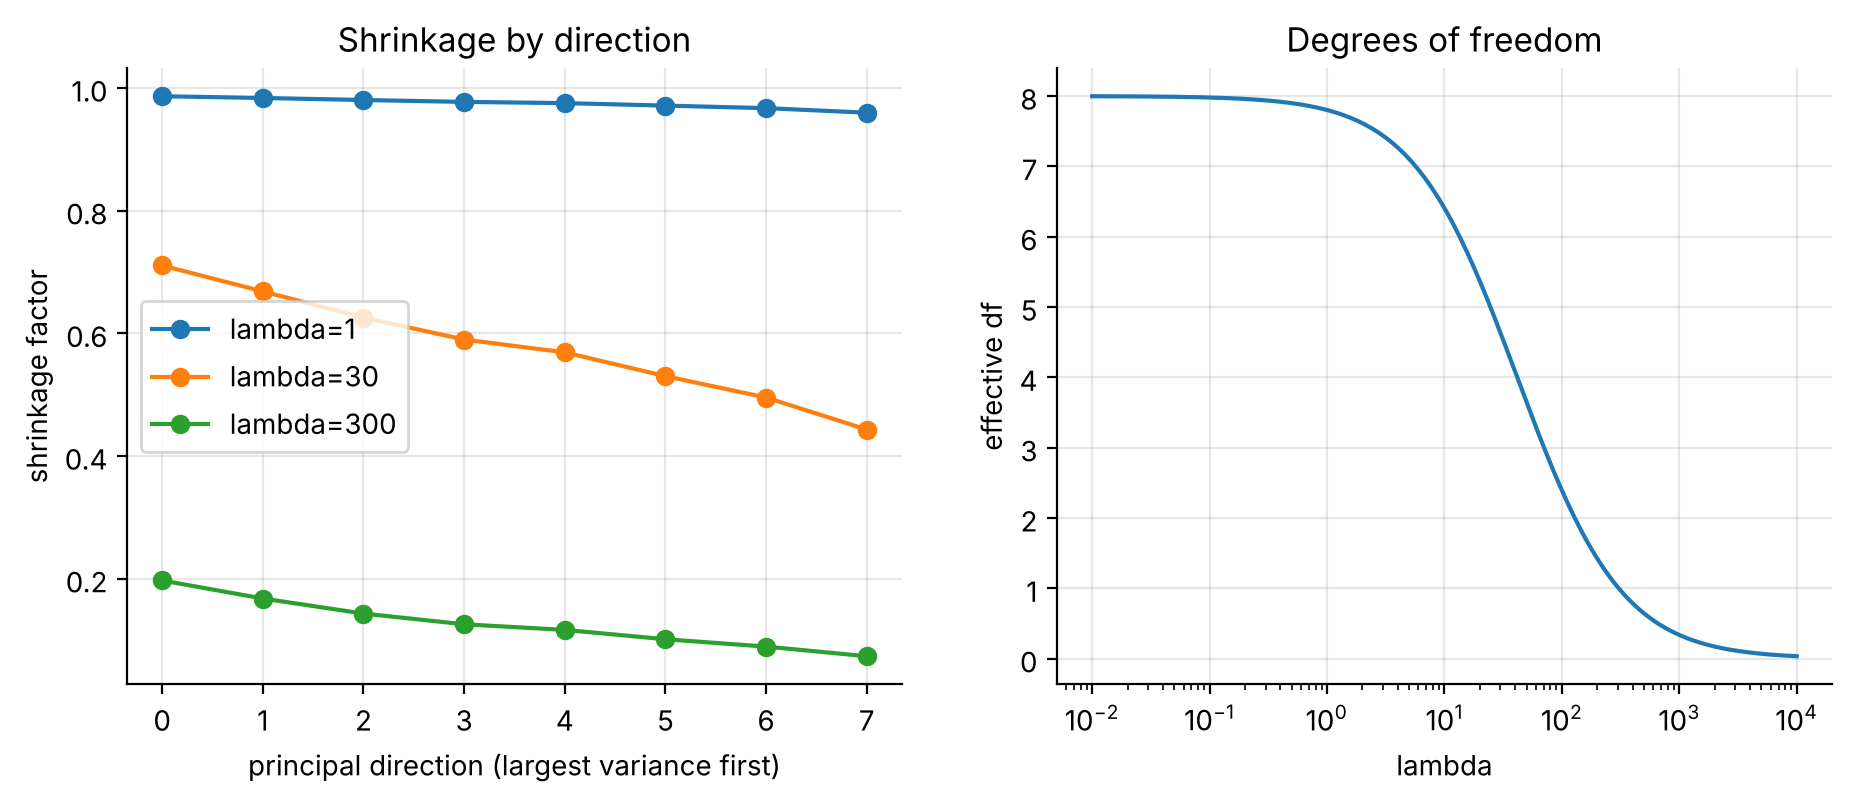

In [3]:
d = np.linalg.svd(Xc, compute_uv=False)
lams = np.logspace(-2, 4, 200)
df = [(d**2 / (d**2 + l)).sum() for l in lams]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for l in [1, 30, 300]:
    ax[0].plot(d**2 / (d**2 + l), "o-", label=f"lambda={l}")
ax[0].set(xlabel="principal direction (largest variance first)", ylabel="shrinkage factor", title="Shrinkage by direction"); ax[0].legend()
ax[1].semilogx(lams, df); ax[1].set(xlabel="lambda", ylabel="effective df", title="Degrees of freedom");

## Coefficient paths
As $\lambda$ grows every coefficient shrinks towards zero, but none reaches exactly zero.

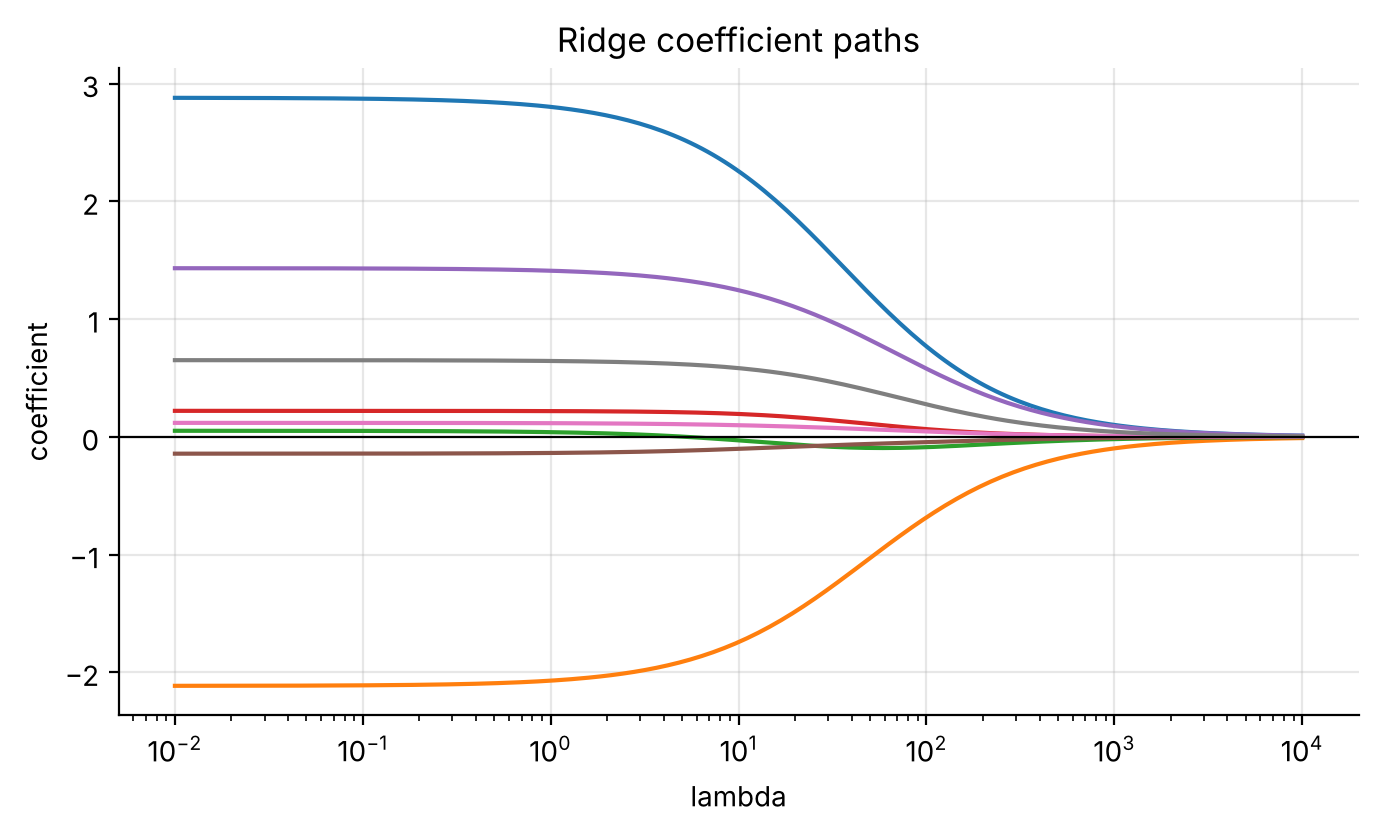

In [4]:
paths = np.array([Ridge(alpha=l).fit(X, y).coef_ for l in lams])
plt.semilogx(lams, paths); plt.axhline(0, color="k", lw=0.8)
plt.xlabel("lambda"); plt.ylabel("coefficient"); plt.title("Ridge coefficient paths");

## Always standardise
The penalty $\sum\beta_j^2$ depends on units. A predictor measured in pence instead of pounds has a
coefficient 100 times smaller and is barely penalised. Standardise each column to mean 0, standard
deviation 1, **using the training sample only**, so the penalty treats predictors equally.

In [5]:
X2 = X.copy(); X2[:, 0] *= 100          # same information, different units
b_raw = Ridge(alpha=lam).fit(X2, y).coef_
print("coef on predictor 0, original units  :", round(Ridge(alpha=lam).fit(X, y).coef_[0], 3))
print("coef on predictor 0, x100 (times 100):", round(b_raw[0] * 100, 3), " <- penalised far less")

coef on predictor 0, original units  : 2.256
coef on predictor 0, x100 (times 100): 2.863  <- penalised far less


## Correlated predictors: ridge shares the weight
With two near-identical predictors OLS coefficients are unstable (they can be +10 and -8).
Ridge splits the effect roughly equally. That is why ridge suits a panel like ours, where
manufacturing output, production output and goods exports move together.

In [6]:
z = rng.normal(size=200)
Xcor = np.c_[z + 0.05 * rng.normal(size=200), z + 0.05 * rng.normal(size=200)]
ycor = 2 * z + rng.normal(size=200)
for i in range(3):
    idx = rng.choice(200, 40, replace=False)
    ols = np.linalg.lstsq(np.c_[np.ones(40), Xcor[idx]], ycor[idx], rcond=None)[0][1:]
    rid = Ridge(alpha=5).fit(Xcor[idx], ycor[idx]).coef_
    print(f"sample {i}: OLS {np.round(ols, 2)}   ridge {np.round(rid, 2)}")

sample 0: OLS [1.7  0.27]   ridge [0.95 0.93]
sample 1: OLS [-0.5   2.34]   ridge [0.85 0.89]
sample 2: OLS [1.24 0.58]   ridge [0.87 0.85]


## Bayesian interpretation
Ridge is the posterior mode (and mean) under a Gaussian prior $\beta_j \sim N(0, \sigma^2/\lambda)$:
a belief that effects are small and spread across many predictors.

**Key takeaways**
* Closed form; works when $p > n$.
* Shrinks hardest along low-variance directions; never selects.
* Standardise on the training sample; leave the intercept unpenalised.